# Day 073 | Time Series Forecasting with LSTM

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning

**Author:** Ripon Chandra Malo

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Sliding window | Create input-output pairs from a time series | Using last 30 days to predict next 7 days |
| Sequence creation | Transform raw data into supervised learning format | Converting settlement records into training data |
| Multi-step forecasting | Predict multiple future values at once | Forecasting settlement 7 days ahead |
| Teacher forcing | Feed true values vs predictions during training | Training strategy for sequence-to-sequence |
| Recursive prediction | Use model output as next input | Rolling forecasts for early warning systems |

---

## Our Geotechnical Problem

An embankment over soft ground has **settlement monitoring sensors** recording daily vertical
displacement for one year (365 data points). We need to **forecast settlement 7 days ahead**
to provide early warning if rates exceed design thresholds.

We will:
1. Generate realistic synthetic daily settlement data
2. Create sliding window sequences for supervised learning
3. Train an LSTM to forecast 7 days ahead
4. Compare single-step vs multi-step forecasting strategies

---

In [1]:
# ───────────────────────────────────────────────────────
# IMPORTS
# ───────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

PyTorch version: 2.5.1
Device: cpu


## Part 1: Generating Synthetic Settlement Data

Real settlement follows a consolidation curve with primary and secondary components.
We model it as:

$$S(t) = S_{\text{primary}} \cdot U(t) + S_{\text{secondary}} \cdot \log(t/t_p) + \text{noise}$$

where $U(t)$ is the degree of consolidation (Terzaghi theory) and the secondary
component kicks in after primary consolidation is mostly complete.

---

In [2]:
# ───────────────────────────────────────────────────────
# GENERATE SYNTHETIC DAILY SETTLEMENT DATA (365 DAYS)
# ───────────────────────────────────────────────────────

def generate_settlement_series(n_days=365, seed=42):
    """
    Generate a realistic settlement time series.
    
    Combines:
    - Primary consolidation (exponential approach to S_primary)
    - Secondary compression (linear in log-time after primary)
    - Sensor noise
    - Seasonal temperature effects on readings
    """
    np.random.seed(seed)
    t = np.arange(1, n_days + 1, dtype=float)  # days 1 to 365
    
    # Primary consolidation parameters
    S_primary = 120.0    # mm — total primary settlement
    cv_tau = 60.0        # days — time constant for primary
    
    # Degree of consolidation (simplified)
    U = 1.0 - np.exp(-t / cv_tau)
    s_primary = S_primary * U
    
    # Secondary compression (starts becoming significant after ~3*tau)
    C_alpha = 2.5  # mm per log cycle
    t_p = 3.0 * cv_tau  # end of primary
    s_secondary = np.where(t > t_p, C_alpha * np.log10(t / t_p), 0.0)
    
    # Seasonal thermal effect on sensor readings (sinusoidal)
    seasonal = 1.5 * np.sin(2 * np.pi * t / 365 - np.pi / 2)
    
    # Sensor noise
    noise = np.random.randn(n_days) * 0.8
    
    # Total settlement (negative = downward)
    settlement = s_primary + s_secondary + seasonal + noise
    
    return t, settlement

days, settlement = generate_settlement_series(365)
print(f"Generated {len(settlement)} days of settlement data")
print(f"Settlement range: {settlement.min():.1f} to {settlement.max():.1f} mm")
print(f"Final settlement: {settlement[-1]:.1f} mm")

Generated 365 days of settlement data
Settlement range: 0.9 to 121.0 mm
Final settlement: 119.5 mm


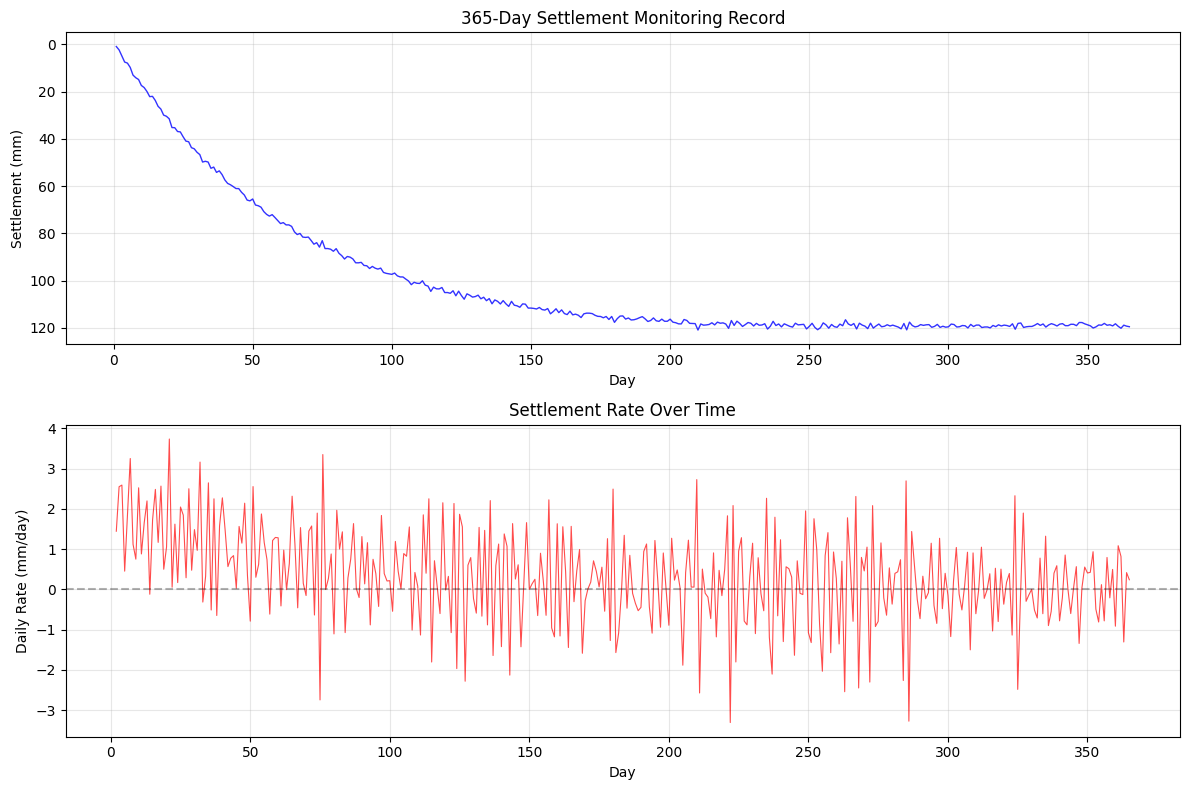

In [3]:
# ───────────────────────────────────────────────────────
# VISUALIZE THE SETTLEMENT TIME SERIES
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Full series
axes[0].plot(days, settlement, 'b-', linewidth=1, alpha=0.8)
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Settlement (mm)')
axes[0].set_title('365-Day Settlement Monitoring Record')
axes[0].grid(True, alpha=0.3)
axes[0].invert_yaxis()  # Settlement is positive downward in our convention

# Daily rate of settlement
rate = np.diff(settlement)
axes[1].plot(days[1:], rate, 'r-', linewidth=0.8, alpha=0.7)
axes[1].axhline(y=0, color='k', linestyle='--', alpha=0.3)
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Daily Rate (mm/day)')
axes[1].set_title('Settlement Rate Over Time')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Part 2: Sliding Window Sequence Creation

To forecast time series, we use a **sliding window** approach:

```
Window size = 30 days,  Forecast horizon = 7 days

Sample 1:  Input: [day 1..30]   -> Target: [day 31..37]
Sample 2:  Input: [day 2..31]   -> Target: [day 32..38]
Sample 3:  Input: [day 3..32]   -> Target: [day 33..39]
...
```

Each training example uses the **last 30 days** to predict the **next 7 days**.

---

In [4]:
# ───────────────────────────────────────────────────────
# CREATE SLIDING WINDOW SEQUENCES
# ───────────────────────────────────────────────────────

def create_sequences(data, window_size=30, horizon=7):
    """
    Create input-output pairs using a sliding window.
    
    Parameters:
    -----------
    data       : 1D array of time series values
    window_size: number of past time steps as input
    horizon    : number of future time steps to predict
    
    Returns:
    --------
    X : (n_samples, window_size, 1)
    y : (n_samples, horizon)
    """
    X, y_out = [], []
    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i:i + window_size])
        y_out.append(data[i + window_size:i + window_size + horizon])
    
    X = np.array(X).reshape(-1, window_size, 1)
    y_out = np.array(y_out)
    return X, y_out

# Normalize the settlement data
s_mean = settlement.mean()
s_std = settlement.std()
settlement_norm = (settlement - s_mean) / s_std

# Create sequences
WINDOW = 30
HORIZON = 7

X_all, y_all = create_sequences(settlement_norm, window_size=WINDOW, horizon=HORIZON)
print(f"Total samples: {X_all.shape[0]}")
print(f"Input shape:   {X_all.shape}  (samples, window, features)")
print(f"Target shape:  {y_all.shape}  (samples, horizon)")

Total samples: 329
Input shape:   (329, 30, 1)  (samples, window, features)
Target shape:  (329, 7)  (samples, horizon)


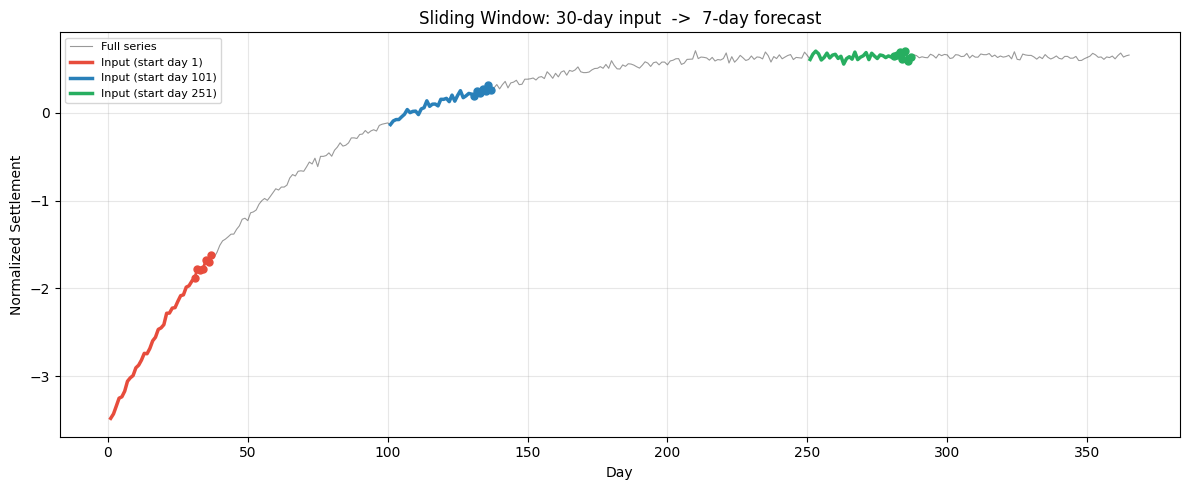

In [5]:
# ───────────────────────────────────────────────────────
# VISUALIZE THE SLIDING WINDOW CONCEPT
# ───────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 5))

# Plot full series
ax.plot(days, settlement_norm, 'k-', linewidth=0.8, alpha=0.4, label='Full series')

# Highlight three example windows
example_indices = [0, 100, 250]
colors_ex = ['#e74c3c', '#2980b9', '#27ae60']

for idx, c in zip(example_indices, colors_ex):
    # Input window
    win_start = idx + 1  # days are 1-indexed
    win_days = np.arange(win_start, win_start + WINDOW)
    ax.plot(win_days, X_all[idx, :, 0], '-', color=c, linewidth=2.5, label=f'Input (start day {win_start})')
    
    # Target horizon
    tgt_days = np.arange(win_start + WINDOW, win_start + WINDOW + HORIZON)
    ax.plot(tgt_days, y_all[idx], 'o-', color=c, linewidth=2, markersize=5)

ax.set_xlabel('Day')
ax.set_ylabel('Normalized Settlement')
ax.set_title(f'Sliding Window: {WINDOW}-day input  ->  {HORIZON}-day forecast')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# ───────────────────────────────────────────────────────
# TRAIN / VALIDATION / TEST SPLIT (chronological)
# ───────────────────────────────────────────────────────

n_total = X_all.shape[0]
n_train = int(n_total * 0.7)
n_val   = int(n_total * 0.15)

X_train = torch.FloatTensor(X_all[:n_train])
y_train = torch.FloatTensor(y_all[:n_train])
X_val   = torch.FloatTensor(X_all[n_train:n_train+n_val])
y_val   = torch.FloatTensor(y_all[n_train:n_train+n_val])
X_test  = torch.FloatTensor(X_all[n_train+n_val:])
y_test  = torch.FloatTensor(y_all[n_train+n_val:])

train_ds = TensorDataset(X_train, y_train)
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)

print(f"Train: {X_train.shape[0]} samples (days 1-{n_train+WINDOW})")
print(f"Val:   {X_val.shape[0]} samples")
print(f"Test:  {X_test.shape[0]} samples")

Train: 230 samples (days 1-260)
Val:   49 samples
Test:  50 samples


## Part 3: LSTM Forecasting Model

Our LSTM takes a sequence of 30 time steps and outputs 7 future values.
We use the **last hidden state** from the LSTM and project it to the forecast horizon.

Architecture: `Input (30, 1) -> LSTM(64) -> FC(7)`

---

In [7]:
# ───────────────────────────────────────────────────────
# LSTM FORECASTING MODEL
# ───────────────────────────────────────────────────────

class LSTMForecaster(nn.Module):
    """LSTM for multi-step settlement forecasting."""
    
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, horizon=7, dropout=0.2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        self.lstm = nn.LSTM(
            input_size, hidden_size, num_layers,
            batch_first=True, dropout=dropout
        )
        
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Linear(32, horizon)
        )
    
    def forward(self, x):
        # x: (batch, window, 1)
        lstm_out, (h_n, c_n) = self.lstm(x)
        
        # Use the last time step output
        last_hidden = lstm_out[:, -1, :]  # (batch, hidden_size)
        forecast = self.fc(last_hidden)    # (batch, horizon)
        return forecast

model = LSTMForecaster(input_size=1, hidden_size=64, num_layers=2, horizon=HORIZON)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,}")
print(f"\nArchitecture:\n{model}")

Model parameters: 52,743

Architecture:
LSTMForecaster(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=7, bias=True)
  )
)


In [8]:
# ───────────────────────────────────────────────────────
# TRAINING LOOP WITH EARLY STOPPING
# ───────────────────────────────────────────────────────

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=10, factor=0.5)

epochs = 150
best_val_loss = float('inf')
patience_counter = 0
patience = 25

train_losses = []
val_losses = []

for epoch in range(epochs):
    # Training
    model.train()
    epoch_loss = 0
    for xb, yb in train_dl:
        pred = model(xb)
        loss = criterion(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()
    
    train_losses.append(epoch_loss / len(train_dl))
    
    # Validation
    model.eval()
    with torch.no_grad():
        val_pred = model(X_val)
        val_loss = criterion(val_pred, y_val).item()
        val_losses.append(val_loss)
    
    scheduler.step(val_loss)
    
    # Early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = model.state_dict().copy()
        patience_counter = 0
    else:
        patience_counter += 1
    
    if (epoch + 1) % 25 == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} | Train: {train_losses[-1]:.6f}  Val: {val_losses[-1]:.6f}")
    
    if patience_counter >= patience:
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

# Restore best model
model.load_state_dict(best_state)
print(f"\nBest validation loss: {best_val_loss:.6f}")

Epoch  25/150 | Train: 0.001094  Val: 0.000750


Epoch  50/150 | Train: 0.001313  Val: 0.000770



Early stopping at epoch 55

Best validation loss: 0.000655


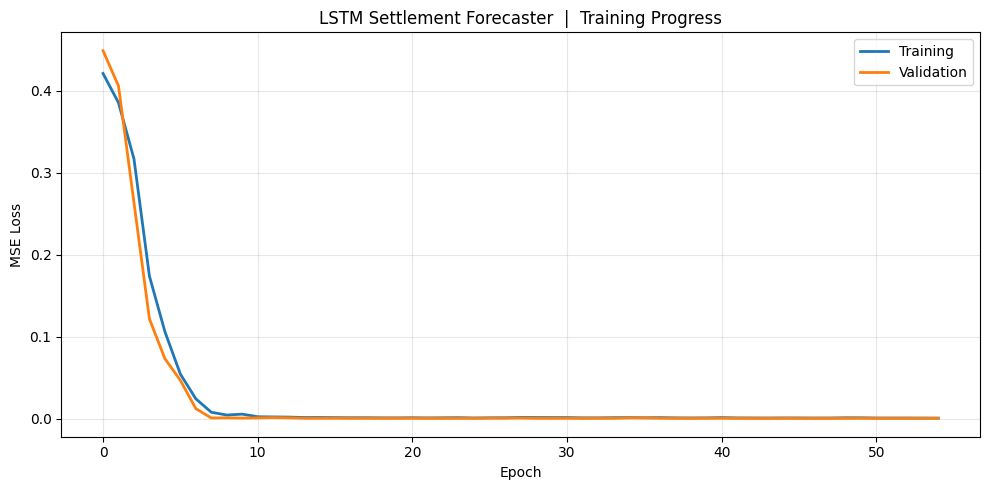

In [9]:
# ───────────────────────────────────────────────────────
# TRAINING CURVES
# ───────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_losses, label='Training', linewidth=2)
ax.plot(val_losses, label='Validation', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.set_title('LSTM Settlement Forecaster  |  Training Progress')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Part 4: Evaluating the 7-Day Forecast

We evaluate on the held-out test set (last portion of the time series).
For each test window, we predict the next 7 days and compare with actual values.

---

In [10]:
# ───────────────────────────────────────────────────────
# TEST SET EVALUATION
# ───────────────────────────────────────────────────────

model.eval()
with torch.no_grad():
    test_pred = model(X_test).numpy()

# Denormalize
test_pred_mm = test_pred * s_std + s_mean
test_true_mm = y_test.numpy() * s_std + s_mean

# Compute metrics per forecast day
print(f"{'Day Ahead':<12} {'MAE (mm)':<12} {'RMSE (mm)':<12}")
print("-" * 36)
for d in range(HORIZON):
    mae = np.abs(test_pred_mm[:, d] - test_true_mm[:, d]).mean()
    rmse = np.sqrt(((test_pred_mm[:, d] - test_true_mm[:, d])**2).mean())
    print(f"  +{d+1:<10d} {mae:<12.3f} {rmse:<12.3f}")

overall_mae = np.abs(test_pred_mm - test_true_mm).mean()
overall_rmse = np.sqrt(((test_pred_mm - test_true_mm)**2).mean())
print("-" * 36)
print(f"{'Overall':<12} {overall_mae:<12.3f} {overall_rmse:<12.3f}")

Day Ahead    MAE (mm)     RMSE (mm)   
------------------------------------
  +1          0.557        0.685       
  +2          0.526        0.648       
  +3          0.510        0.628       
  +4          0.532        0.659       
  +5          0.527        0.658       
  +6          0.523        0.654       
  +7          0.573        0.711       
------------------------------------
Overall      0.535        0.664       


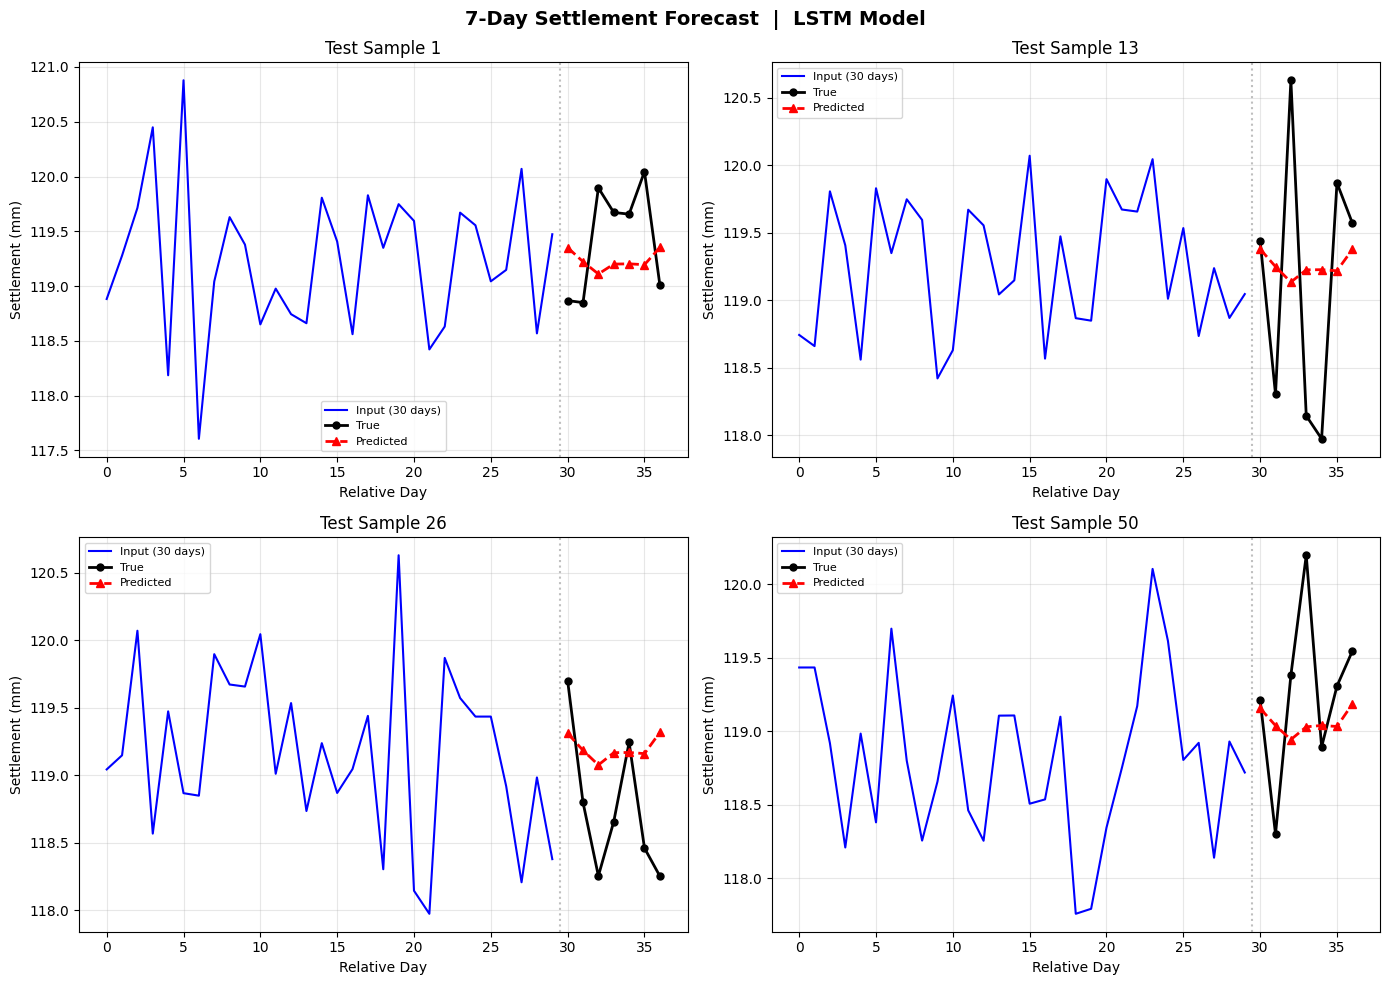

In [11]:
# ───────────────────────────────────────────────────────
# VISUALIZE FORECASTS ON TEST SET
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

test_indices = [0, len(X_test)//4, len(X_test)//2, len(X_test)-1]

for ax, idx in zip(axes, test_indices):
    # Input window (denormalized)
    input_vals = X_test[idx, :, 0].numpy() * s_std + s_mean
    input_days = np.arange(WINDOW)
    
    # True future
    true_future = test_true_mm[idx]
    future_days = np.arange(WINDOW, WINDOW + HORIZON)
    
    # Predicted future
    pred_future = test_pred_mm[idx]
    
    ax.plot(input_days, input_vals, 'b-', linewidth=1.5, label='Input (30 days)')
    ax.plot(future_days, true_future, 'ko-', linewidth=2, markersize=5, label='True')
    ax.plot(future_days, pred_future, 'r^--', linewidth=2, markersize=6, label='Predicted')
    ax.axvline(x=WINDOW-0.5, color='gray', linestyle=':', alpha=0.5)
    
    ax.set_xlabel('Relative Day')
    ax.set_ylabel('Settlement (mm)')
    ax.set_title(f'Test Sample {idx+1}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.suptitle('7-Day Settlement Forecast  |  LSTM Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Part 5: Recursive Multi-Step Forecasting

An alternative to direct multi-step forecasting is **recursive** prediction:
predict one step, append it to the input, and predict the next step.

This can extend forecasts beyond the trained horizon but accumulates error.

---

In [12]:
# ───────────────────────────────────────────────────────
# SINGLE-STEP MODEL FOR RECURSIVE FORECASTING
# ───────────────────────────────────────────────────────

class LSTMOneStep(nn.Module):
    """LSTM that predicts one step ahead."""
    
    def __init__(self, input_size=1, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                           batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)
    
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        return self.fc(lstm_out[:, -1, :])  # predict next step only

# Create single-step training data
X_1step, y_1step = create_sequences(settlement_norm, window_size=WINDOW, horizon=1)
y_1step = y_1step.squeeze()

X_1_train = torch.FloatTensor(X_1step[:n_train])
y_1_train = torch.FloatTensor(y_1step[:n_train])
train_ds_1 = TensorDataset(X_1_train, y_1_train)
train_dl_1 = DataLoader(train_ds_1, batch_size=32, shuffle=True)

# Train single-step model
torch.manual_seed(42)
model_1step = LSTMOneStep()
opt_1 = torch.optim.Adam(model_1step.parameters(), lr=0.001)
crit = nn.MSELoss()

for epoch in range(100):
    model_1step.train()
    for xb, yb in train_dl_1:
        pred = model_1step(xb).squeeze()
        loss = crit(pred, yb)
        opt_1.zero_grad()
        loss.backward()
        opt_1.step()
    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch+1}/100 | Loss: {loss.item():.6f}")

print("Single-step model trained.")

Epoch 50/100 | Loss: 0.000609


Epoch 100/100 | Loss: 0.002315
Single-step model trained.


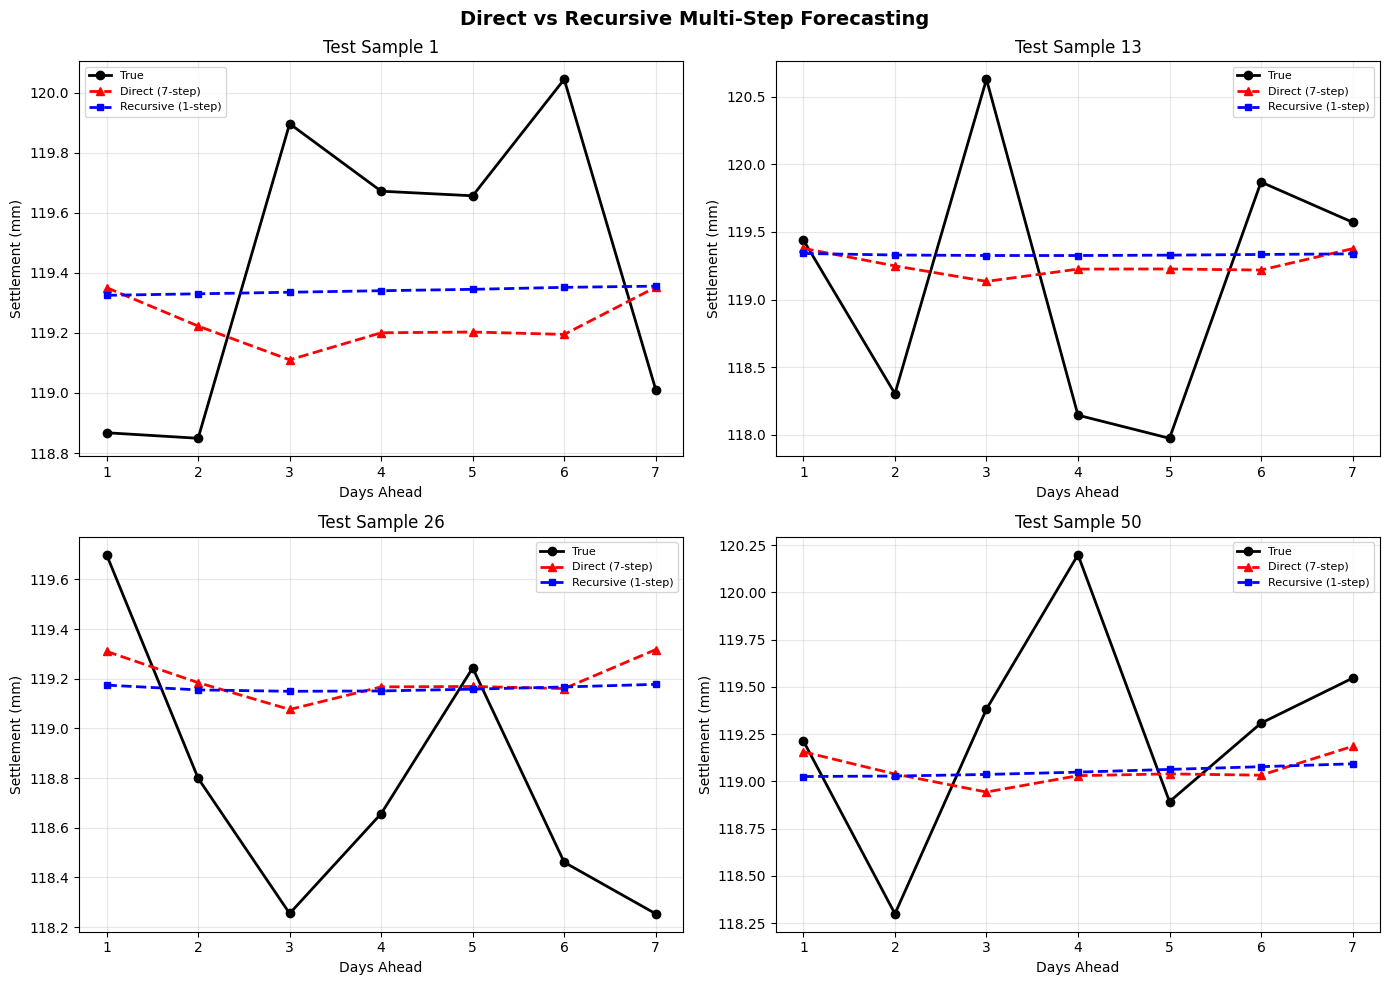

In [13]:
# ───────────────────────────────────────────────────────
# RECURSIVE FORECASTING: PREDICT 7 STEPS ONE AT A TIME
# ───────────────────────────────────────────────────────

def recursive_forecast(model, initial_window, n_steps=7):
    """Recursively predict n_steps into the future."""
    model.eval()
    current_window = initial_window.clone()  # (1, window, 1)
    predictions = []
    
    with torch.no_grad():
        for _ in range(n_steps):
            next_val = model(current_window)  # (1, 1)
            predictions.append(next_val.item())
            # Shift window: drop oldest, append prediction
            new_input = next_val.unsqueeze(-1)  # (1, 1, 1)
            current_window = torch.cat([current_window[:, 1:, :], new_input], dim=1)
    
    return np.array(predictions)

# Compare direct vs recursive on test samples
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, idx in zip(axes, test_indices):
    true_future = test_true_mm[idx]
    direct_pred = test_pred_mm[idx]
    
    # Recursive prediction
    rec_pred_norm = recursive_forecast(model_1step, X_test[idx:idx+1], n_steps=HORIZON)
    rec_pred_mm = rec_pred_norm * s_std + s_mean
    
    future_days = np.arange(1, HORIZON + 1)
    
    ax.plot(future_days, true_future, 'ko-', linewidth=2, markersize=6, label='True')
    ax.plot(future_days, direct_pred, 'r^--', linewidth=2, markersize=6, label='Direct (7-step)')
    ax.plot(future_days, rec_pred_mm, 'bs--', linewidth=2, markersize=5, label='Recursive (1-step)')
    
    ax.set_xlabel('Days Ahead')
    ax.set_ylabel('Settlement (mm)')
    ax.set_title(f'Test Sample {idx+1}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.suptitle('Direct vs Recursive Multi-Step Forecasting', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

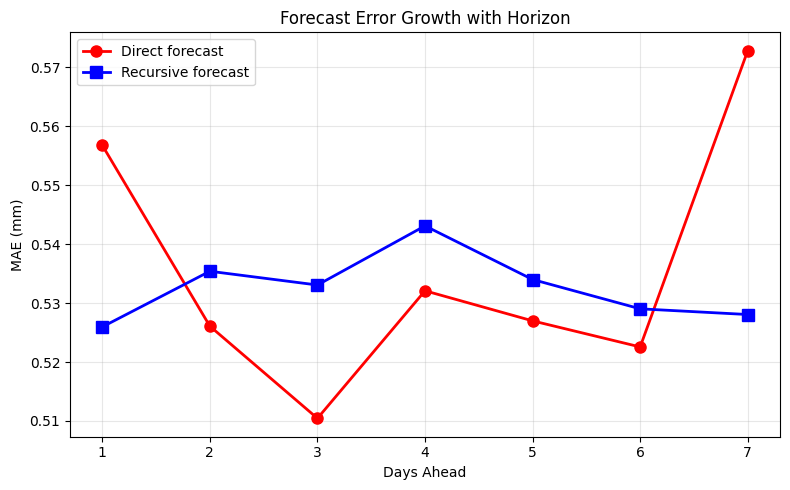

In [14]:
# ───────────────────────────────────────────────────────
# ERROR GROWTH WITH FORECAST HORIZON
# ───────────────────────────────────────────────────────

# Compute MAE per forecast day for both strategies
direct_mae_per_day = []
recursive_mae_per_day = []

all_rec_preds = []
for i in range(len(X_test)):
    rec = recursive_forecast(model_1step, X_test[i:i+1], n_steps=HORIZON)
    all_rec_preds.append(rec)
all_rec_preds = np.array(all_rec_preds) * s_std + s_mean

for d in range(HORIZON):
    direct_mae_per_day.append(np.abs(test_pred_mm[:, d] - test_true_mm[:, d]).mean())
    recursive_mae_per_day.append(np.abs(all_rec_preds[:, d] - test_true_mm[:, d]).mean())

fig, ax = plt.subplots(figsize=(8, 5))
days_ahead = np.arange(1, HORIZON + 1)
ax.plot(days_ahead, direct_mae_per_day, 'ro-', linewidth=2, markersize=8, label='Direct forecast')
ax.plot(days_ahead, recursive_mae_per_day, 'bs-', linewidth=2, markersize=8, label='Recursive forecast')

ax.set_xlabel('Days Ahead')
ax.set_ylabel('MAE (mm)')
ax.set_title('Forecast Error Growth with Horizon')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Practice Exercises

Try these exercises to deepen your understanding:

```python
# Exercise 1: Different window sizes
# Try WINDOW = 14, 30, 60 and compare forecast accuracy.
# Is a longer lookback always better?

# Exercise 2: Multiple features
# Add settlement RATE as a second input feature.
# Modify input_size=2 in the model and data preparation.

# Exercise 3: Longer forecast horizon
# Increase HORIZON to 14 or 30 days.
# How does accuracy degrade with longer forecasts?

# Exercise 4: GRU comparison
# Replace nn.LSTM with nn.GRU in the forecaster.
# Does GRU train faster? Is accuracy similar?
```

---

## Key Takeaways

1. **Sliding windows** convert raw time series into supervised learning format
2. **LSTM captures temporal patterns** in settlement data for accurate forecasting
3. **Direct multi-step** predicts all future steps at once, avoiding error accumulation
4. **Recursive forecasting** can extend to arbitrary horizons but errors compound
5. **Forecast accuracy degrades** with increasing horizon — critical for setting warning thresholds

---

## How This Connects

| ML Concept | Geotechnical Application |
|-----------|------------------------|
| Sliding window | Using recent monitoring history as model input |
| Multi-step forecast | Predicting settlement 7 days ahead for early warnings |
| Chronological split | Never training on future data in time series |
| Error growth | Understanding forecast reliability windows |
| Early stopping | Preventing overfitting to noisy field measurements |